In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from pathlib import Path
from skimage import io, filters, morphology, measure, segmentation
from skimage.feature import peak_local_max
from scipy import ndimage as ndi

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# Functions

In [ ]:
def show_one_focus(image, df, index, radius_factor=2, padding=30):

    # Select focus by DataFrame index
    row = df.loc[index]

    x = float(row["x_pixel"])
    y = float(row["y_pixel"])
    sigma = float(row["sigma_pixel"])
    sigma_nm = float(row["sigma_nm"])
    foci_MFI = float(row["foci_MFI"])

    # Radius based on sigma
    radius = radius_factor * sigma

    H, W = image.shape[:2]

    # Crop around the focus
    margin = max(padding, int(np.ceil(radius + 10)))

    x0 = max(0, int(x - margin))
    x1 = min(W, int(x + margin + 1))
    y0 = max(0, int(y - margin))
    y1 = min(H, int(y + margin + 1))

    crop = image[y0:y1, x0:x1]

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original image
    axes[0].imshow(crop, cmap="gray")
    axes[0].set_title(f"Index: {index}")

    # Image with focus boundary
    axes[1].imshow(crop, cmap="gray")

    circle = Circle(
        (x - x0, y - y0),
        radius=radius,
        edgecolor="red",
        facecolor="none",
        linewidth=1.5
    )

    axes[1].add_patch(circle)

    axes[1].set_title(
        f"Index: {index}\n"
        f"Sigma, nm: {sigma_nm:.2f} nm\n"
        f"Foci MFI: {foci_MFI:.2f}",
    )

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    
def show_selected_foci(
    image,
    df,
    indexes,
    radius_factor=2,
    padding=30
):
    # Allow a single index or a list of indices
    if isinstance(indexes, (int, np.integer)):
        indexes = [indexes]

    # Select foci by DataFrame index
    subset = df.loc[indexes]

    if subset.empty:
        print("No foci selected.")
        return

    H, W = image.shape[:2]
    n = len(subset)

    # Create two panels per focus
    fig, axes = plt.subplots(
        n, 2,
        figsize=(10, 4 * n),
        squeeze=False
    )

    for i, (index, row) in enumerate(subset.iterrows()):

        # Focus properties
        x = float(row["x_pixel"])
        y = float(row["y_pixel"])
        sigma = float(row["sigma_pixel"])
        sigma_nm = float(row["sigma_nm"])
        foci_MFI = float(row["foci_MFI"])

        # Circle radius
        radius = radius_factor * sigma

        # Crop around the focus
        margin = max(padding, int(np.ceil(radius + 10)))

        x0 = max(0, int(np.floor(x - margin)))
        x1 = min(W, int(np.ceil(x + margin + 1)))
        y0 = max(0, int(np.floor(y - margin)))
        y1 = min(H, int(np.ceil(y + margin + 1)))

        crop = image[y0:y1, x0:x1]

        if crop.size == 0:
            print(f"Skipping index {index}: outside image.")
            axes[i, 0].axis("off")
            axes[i, 1].axis("off")
            continue

        # Original image
        axes[i, 0].imshow(crop, cmap="gray")
        axes[i, 0].set_title(
            f"Index: {index}",
            fontsize=11
        )

        # Image with focus boundary
        axes[i, 1].imshow(crop, cmap="gray")

        circle = Circle(
            (x - x0, y - y0),
            radius=radius,
            edgecolor="red",
            facecolor="none",
            linewidth=1.5
        )

        axes[i, 1].add_patch(circle)

        axes[i, 1].set_title(
            f"Index: {index}\n"
            f"Sigma: {sigma_nm:.2f} nm\n"
            f"Foci MFI: {foci_MFI:.2f}",
            fontsize=11
        )

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

# Import data

## Import image

Image shape: (512, 512)
Data type: uint16


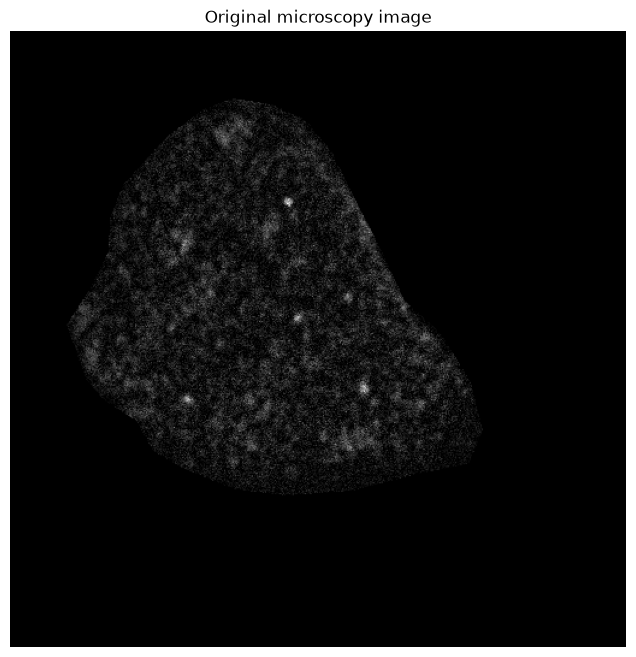

In [2]:
image_path = "test.tif"

image = io.imread(image_path)

print("Image shape:", image.shape)
print("Data type:", image.dtype)

fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")
ax.set_title("Original microscopy image")
ax.axis("off")

plt.show()

## Import ThunderSTORM data

In [5]:
df = pd.read_csv("test.csv")
df.shape

(273, 10)

## Visualization

In [125]:
inxs = list(df[df['sigma_nm'] > 150].index)

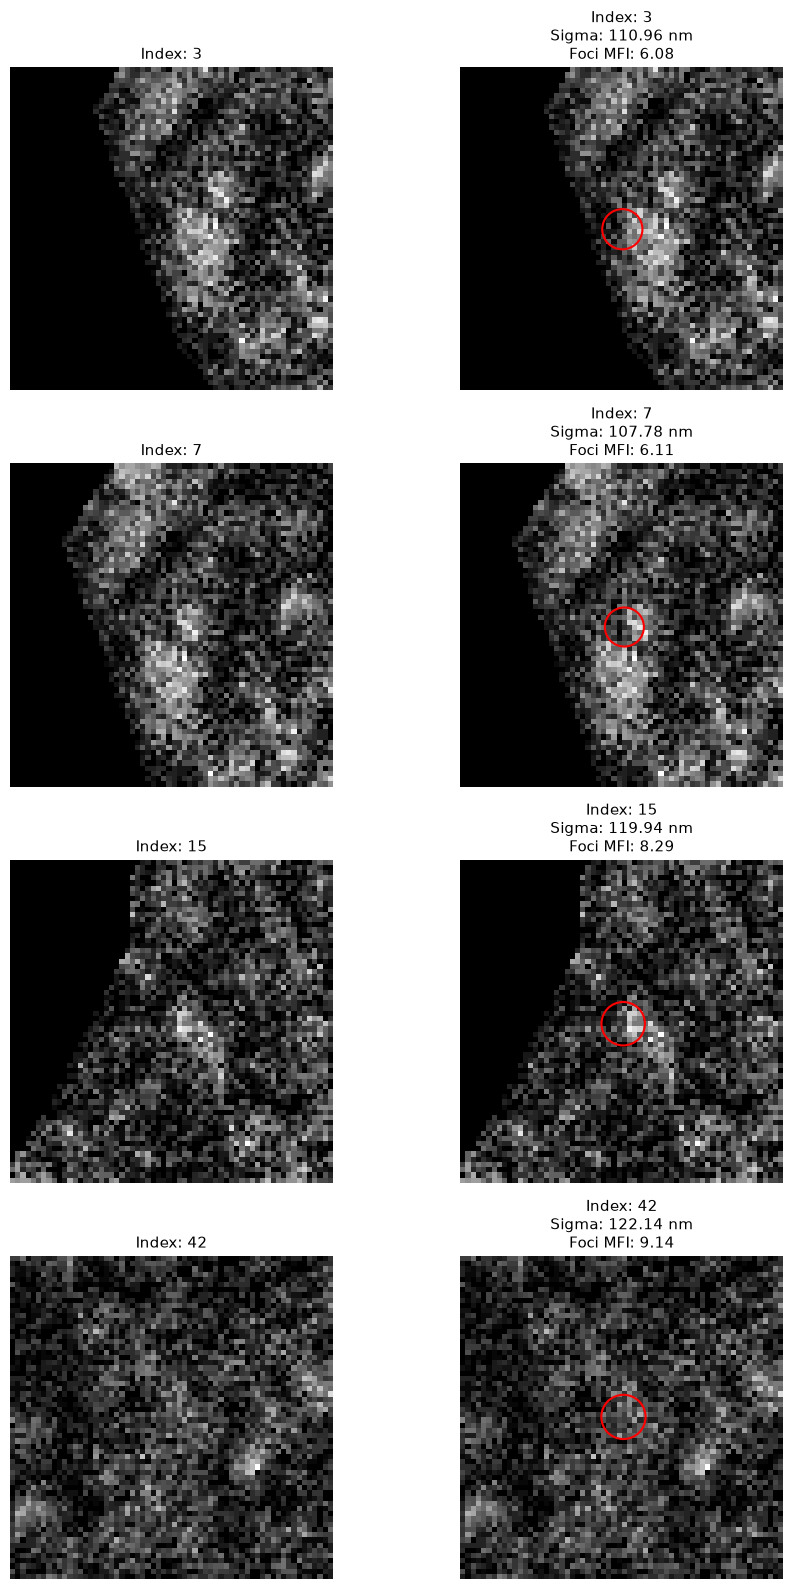

In [ ]:
show_selected_foci(
    image,
    df,
    indexes=inxs
)

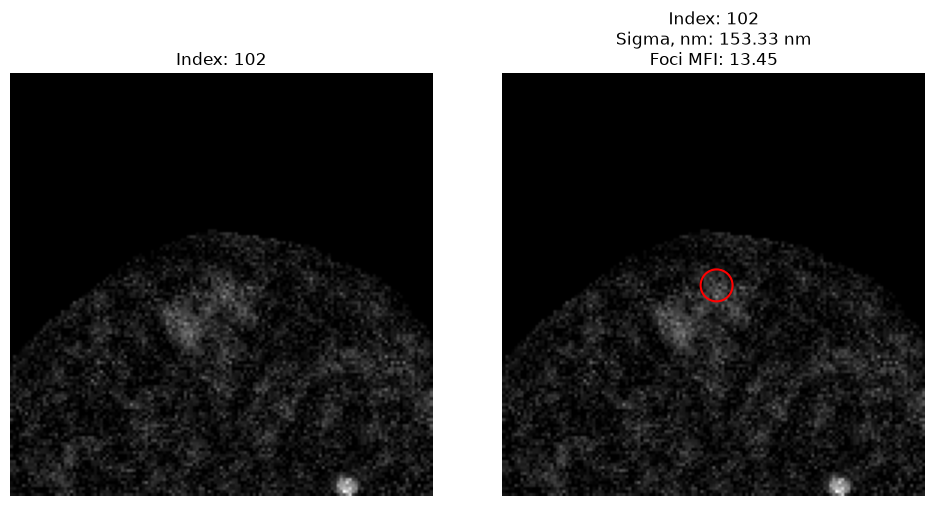

In [119]:
i = 102

show_one_focus(image, df, index=i, padding=70)

# Random Forest

## Import labelled data

In [ ]:
df_labelled = pd.read_csv("test_labelled.csv",  sep=";", encoding="cp1252")
df = df_labelled.dropna(subset=["Class"]).copy()

In [ ]:


# Features for classification
features = [
    "sigma_nm",
    "intensity_photon",
    "foci_MFI",
    "foci_SD"
]

# Copy original DataFrame
data = df.copy()

# Clean class labels
data["Class"] = (
    data["Class"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Convert features to numeric
for feature in features:
    data[feature] = pd.to_numeric(
        data[feature],
        errors="coerce"
    )

# Manually labeled objects
labeled = data[
    data["Class"].isin(["foci", "aggregate"])
].dropna(subset=features).copy()

print("Training samples:")
print(labeled["Class"].value_counts())

In [ ]:
X = labeled[features]
y = labeled["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

In [ ]:
y_pred = rf.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues"
)

plt.title("Random Forest — Confusion Matrix")
plt.show()

In [ ]:
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))

importance.plot.barh(ax=ax)

ax.set_xlabel("Feature importance")
ax.set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.show()

In [ ]:
# Select objects that were not manually classified
unknown_mask = ~data["Class"].isin(["foci", "aggregate"])

# Only predict objects with valid measurements
valid_mask = data[features].notna().all(axis=1)

predict_mask = unknown_mask & valid_mask

X_unknown = data.loc[predict_mask, features]

# Predicted classes
data["Predicted_Class"] = data["Class"]

data.loc[predict_mask, "Predicted_Class"] = rf.predict(
    X_unknown
)

# Prediction probabilities
probabilities = rf.predict_proba(X_unknown)

data["Confidence"] = np.nan

data.loc[predict_mask, "Confidence"] = probabilities.max(axis=1)

display(
    data[["Class", "Predicted_Class", "Confidence"]].head(20)
)

In [ ]:
data["Review"] = False

data.loc[predict_mask, "Review"] = (
    data.loc[predict_mask, "Confidence"] < 0.8
)

display(
    data.loc[
        data["Review"],
        ["Predicted_Class", "Confidence"] + features
    ]
)

In [ ]:
def plot_rf_predictions(image, data):

    colors = {
        "foci": "lime",
        "aggregate": "red"
    }

    fig, ax = plt.subplots(figsize=(10, 10))

    ax.imshow(image, cmap="gray")

    for class_name, color in colors.items():

        subset = data[
            data["Predicted_Class"] == class_name
        ]

        ax.scatter(
            subset["x_pixel"],
            subset["y_pixel"],
            s=50,
            facecolors="none",
            edgecolors=color,
            linewidths=1.2,
            label=f"{class_name}: {len(subset)}"
        )

    ax.legend()
    ax.set_title("Random Forest classification")
    ax.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
plot_rf_predictions(image, data)